# Capstone Project 3
## Social Media Usage and Emotional Well-Being
**Name: Himani Verma**

This project compares classification models to predict the dominant
emotion from social media usage data.

### Data Cleaning
The CSV files had formatting errors and some swapped Age and Gender
values. These were corrected. One invalid Gender value was marked as
missing, and one record with the unclear emotion label "Agression"
was excluded.

Many records were repeated within and across the supplied files.
After removing duplicates, 265 unique
records remained.

These were divided into 159 training, 53 validation and 53 test
records, with all six emotions represented in each set.
User_ID was excluded from the model inputs.

Dataset source: https://www.kaggle.com/datasets/emirhanai/social-media-usage-and-emotional-well-being/

To rerun: place train.csv, val.csv and test.csv beside this notebook. Run cells from top to bottom.


In [7]:
import csv
import pandas as pd

def load_repaired_csv(filename):
    records = []
    repairs = []

    with open(filename, "r", encoding="utf-8-sig", newline="") as file:
        reader = csv.reader(file)
        header = next(reader)

        for row in reader:
            line = reader.line_num

            if not row:
                continue

            if filename == "train.csv" and len(row) == 2 and row[0] == "Tabii":
                repairs.append((line, "Removed non-data text"))
                continue

            if len(row) == 11 and row[-2] == "":
                row.pop(-2)
                repairs.append((line, "Removed extra empty field"))

            elif len(row) == 11 and row[1] == "Female" and row[2].isdigit():
                row.pop(1)
                repairs.append((line, "Removed extra Female field"))

            elif len(row) == 9 and row[1] in ["Female", "Male", "Non-binary"]:
                row.insert(0, None)
                repairs.append((line, "Marked missing User_ID as blank"))

            if len(row) != len(header):
                raise ValueError(f"Unresolved formatting issue: {filename}, line {line}")

            records.append(row)

    print(f"\n{filename}: {len(records)} rows loaded")
    for line, action in repairs:
        print(f"  Line {line}: {action}")

    return pd.DataFrame(records, columns=header)

train_df = load_repaired_csv("train.csv")
val_df = load_repaired_csv("val.csv")
test_df = load_repaired_csv("test.csv")

display(train_df.head())


train.csv: 1000 rows loaded
  Line 1285: Removed non-data text

val.csv: 148 rows loaded
  Line 91: Removed extra empty field
  Line 159: Removed extra Female field
  Line 189: Marked missing User_ID as blank
  Line 201: Removed extra empty field

test.csv: 103 rows loaded


,User_ID,Age,Gender,Platform,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day,Dominant_Emotion
0,1,25,Female,Instagram,120,3,45,10,12,Happiness
1,2,30,Male,Twitter,90,5,20,25,30,Anger
2,3,22,Non-binary,Facebook,60,2,15,5,20,Neutral
3,4,28,Female,Instagram,200,8,100,30,50,Anxiety
4,5,33,Male,LinkedIn,45,1,5,2,10,Boredom


In [ ]:
numeric_columns = [
    "User_ID",
    "Age",
    "Daily_Usage_Time (minutes)",
    "Posts_Per_Day",
    "Likes_Received_Per_Day",
    "Comments_Received_Per_Day",
    "Messages_Sent_Per_Day"
]

# Reload to recover the original text values.
train_df = load_repaired_csv("train.csv")
val_df = load_repaired_csv("val.csv")
test_df = load_repaired_csv("test.csv")

valid_genders = ["Female", "Male", "Non-binary"]

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    for column in df.columns:
        df[column] = df[column].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )
    df.replace("", pd.NA, inplace=True)

    # Swap only where Age contains a gender and Gender contains a number.
    swapped = (
        df["Age"].isin(valid_genders)
        & pd.to_numeric(df["Gender"], errors="coerce").notna()
    )

    original_age = df.loc[swapped, "Age"].copy()
    df.loc[swapped, "Age"] = df.loc[swapped, "Gender"]
    df.loc[swapped, "Gender"] = original_age

    for column in numeric_columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    print(f"\n{name}: corrected {swapped.sum()} swapped rows")
    print("Missing ages:", df["Age"].isna().sum())

    unusual = (
        ~df["Gender"].isin(valid_genders)
        | ~df["Dominant_Emotion"].isin(train_df["Dominant_Emotion"].dropna().unique())
    )

    print("Rows with unusual gender or emotion labels:")
    display(df.loc[unusual])

In [10]:
# Preserve the original datasets before further cleaning.
train_clean = train_df.copy()
val_clean = val_df.copy()
test_clean = test_df.copy()

test_clean.loc[
    ~test_clean["Gender"].isin(valid_genders), "Gender"
] = pd.NA

# Compare records without User_ID, which will not be a model input.
record_columns = [
    column for column in train_clean.columns
    if column != "User_ID"
]

for name, df in [
    ("TRAIN", train_clean),
    ("VALIDATION", val_clean),
    ("TEST", test_clean)
]:
    print(f"{name}: {df.duplicated(subset=record_columns).sum()} duplicate records")

def record_keys(df):
    return set(
        df[record_columns]
        .fillna("<MISSING>")
        .itertuples(index=False, name=None)
    )

train_keys = record_keys(train_clean)
val_keys = record_keys(val_clean)
test_keys = record_keys(test_clean)

print("\nShared unique records:")
print("Train and validation:", len(train_keys & val_keys))
print("Train and test:", len(train_keys & test_keys))
print("Validation and test:", len(val_keys & test_keys))

print("\nValidation emotion counts:")
print(val_clean["Dominant_Emotion"].value_counts())

TRAIN: 800 duplicate records
VALIDATION: 27 duplicate records
TEST: 28 duplicate records

Shared unique records:
Train and validation: 64
Train and test: 66
Validation and test: 30

Validation emotion counts:
Dominant_Emotion
Anxiety      32
Neutral      30
Happiness    28
Sadness      25
Boredom      18
Anger        14
Agression     1
Name: count, dtype: int64


In [11]:
# Combine copies so we can rebuild splits without overlapping records.
combined_df = pd.concat(
    [train_clean, val_clean, test_clean],
    ignore_index=True
)

# Keep the uncertain label separately for documentation.
uncertain_labels = combined_df[
    combined_df["Dominant_Emotion"] == "Agression"
].copy()

combined_df = combined_df[
    combined_df["Dominant_Emotion"] != "Agression"
].copy()

# User_ID is an identifier, not a prediction feature.
combined_df = combined_df.drop(columns="User_ID")

# Remove exact duplicate records.
unique_df = combined_df.drop_duplicates().reset_index(drop=True)

feature_columns = [
    column for column in unique_df.columns
    if column != "Dominant_Emotion"
]

# Find identical inputs assigned more than one emotion.
label_counts = (
    unique_df.groupby(feature_columns, dropna=False)["Dominant_Emotion"]
    .nunique()
)

print("Rows set aside for uncertain emotion:", len(uncertain_labels))
print("Unique records remaining:", len(unique_df))
print("Input combinations with conflicting emotions:", (label_counts > 1).sum())

print("\nEmotion counts:")
print(unique_df["Dominant_Emotion"].value_counts())

Rows set aside for uncertain emotion: 1
Unique records remaining: 265
Input combinations with conflicting emotions: 0

Emotion counts:
Dominant_Emotion
Happiness    55
Neutral      52
Anxiety      46
Sadness      44
Boredom      36
Anger        32
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

# Reserve 20% for final testing.
development_df, test_data = train_test_split(
    unique_df,
    test_size=0.20,
    stratify=unique_df["Dominant_Emotion"],
    random_state=42
)

# Use 25% of the remaining 80% for validation.
train_data, val_data = train_test_split(
    development_df,
    test_size=0.25,
    stratify=development_df["Dominant_Emotion"],
    random_state=42
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))
print("Testing rows:", len(test_data))

print("\nEmotion distribution:")
display(pd.DataFrame({
    "Train": train_data["Dominant_Emotion"].value_counts(),
    "Validation": val_data["Dominant_Emotion"].value_counts(),
    "Test": test_data["Dominant_Emotion"].value_counts()
}).fillna(0).astype(int))

Training rows: 159
Validation rows: 53
Testing rows: 53

Emotion distribution:


,Train,Validation,Test
Dominant_Emotion,,,
Anger,19,6,7
Anxiety,28,9,9
Boredom,22,7,7
Happiness,33,11,11
Neutral,31,11,10
Sadness,26,9,9


In [13]:
print("TRAINING DATA SUMMARY")
display(train_data.describe().round(2))

print("\nMissing values:")
print(train_data.isna().sum())

print("\nColumn data types:")
print(train_data.dtypes)

TRAINING DATA SUMMARY


,Age,Daily_Usage_Time (minutes),Posts_Per_Day,Likes_Received_Per_Day,Comments_Received_Per_Day,Messages_Sent_Per_Day
count,159.00,159.0,159.00,159.00,159.00,159.00
mean,27.67,96.3,3.45,38.82,14.45,22.74
std,4.08,41.5,2.03,26.66,8.56,9.05
min,21.00,30.0,1.00,5.00,2.00,8.00
25%,24.00,65.0,2.00,18.00,7.00,15.00
50%,28.00,90.0,3.00,32.00,12.00,22.00
75%,31.00,120.0,5.00,55.00,20.00,28.00
max,35.00,200.0,10.00,110.00,40.00,50.00



Missing values:
Age                           0
Gender                        1
Platform                      0
Daily_Usage_Time (minutes)    0
Posts_Per_Day                 0
Likes_Received_Per_Day        0
Comments_Received_Per_Day     0
Messages_Sent_Per_Day         0
Dominant_Emotion              0
dtype: int64

Column data types:
Age                            int64
Gender                        object
Platform                      object
Daily_Usage_Time (minutes)     int64
Posts_Per_Day                  int64
Likes_Received_Per_Day         int64
Comments_Received_Per_Day      int64
Messages_Sent_Per_Day          int64
Dominant_Emotion              object
dtype: object


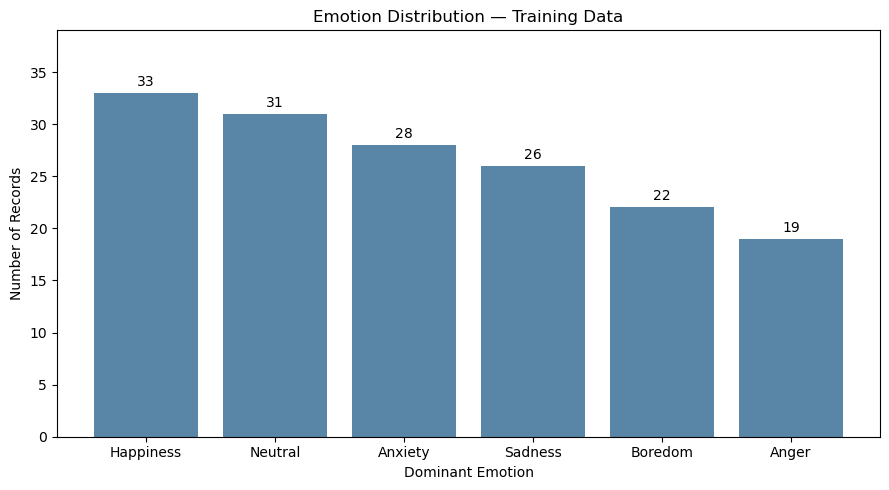

In [14]:
import matplotlib.pyplot as plt

emotion_counts = train_data["Dominant_Emotion"].value_counts()

plt.figure(figsize=(9, 5))
bars = plt.bar(
    emotion_counts.index,
    emotion_counts.values,
    color="#5986A6"
)

plt.bar_label(bars, padding=3)
plt.title("Emotion Distribution — Training Data")
plt.xlabel("Dominant Emotion")
plt.ylabel("Number of Records")
plt.ylim(0, emotion_counts.max() + 6)
plt.tight_layout()
plt.show()

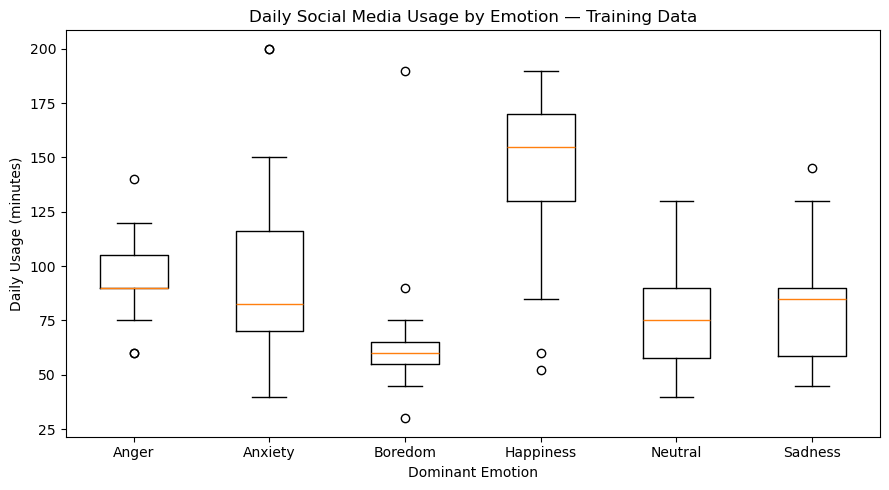

Average daily usage by emotion:
Dominant_Emotion
Happiness    146.3
Anxiety       97.1
Anger         94.2
Sadness       81.9
Neutral       77.3
Boredom       65.9
Name: Daily_Usage_Time (minutes), dtype: float64


In [15]:
emotion_order = sorted(train_data["Dominant_Emotion"].unique())

usage_groups = [
    train_data.loc[
        train_data["Dominant_Emotion"] == emotion,
        "Daily_Usage_Time (minutes)"
    ]
    for emotion in emotion_order
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(usage_groups)
ax.set_xticks(range(1, len(emotion_order) + 1))
ax.set_xticklabels(emotion_order)
ax.set_title("Daily Social Media Usage by Emotion — Training Data")
ax.set_xlabel("Dominant Emotion")
ax.set_ylabel("Daily Usage (minutes)")
plt.tight_layout()
plt.show()

print("Average daily usage by emotion:")
print(
    train_data.groupby("Dominant_Emotion")["Daily_Usage_Time (minutes)"]
    .mean()
    .sort_values(ascending=False)
    .round(1)
)

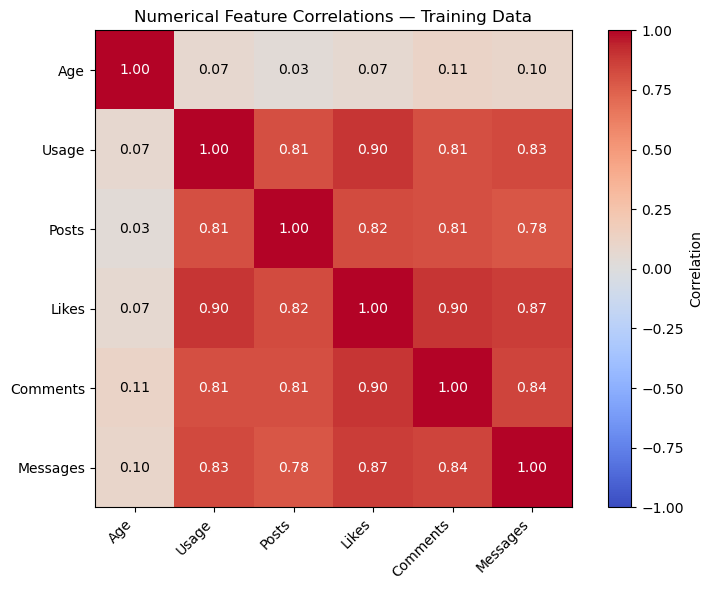

In [16]:
import numpy as np

correlation = train_data.select_dtypes(include="number").corr()

short_labels = [
    "Age", "Usage", "Posts", "Likes", "Comments", "Messages"
]

fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=45, ha="right")
ax.set_yticklabels(short_labels)

for i in range(len(short_labels)):
    for j in range(len(short_labels)):
        value = correlation.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center", va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

fig.colorbar(heatmap, ax=ax, label="Correlation")
ax.set_title("Numerical Feature Correlations — Training Data")
plt.tight_layout()
plt.show()

In [17]:
target_column = "Dominant_Emotion"

X_train = train_data.drop(columns=target_column).copy()
y_train = train_data[target_column].copy()

X_val = val_data.drop(columns=target_column).copy()
y_val = val_data[target_column].copy()

X_test = test_data.drop(columns=target_column).copy()
y_test = test_data[target_column].copy()


for inputs in [X_train, X_val, X_test]:
    inputs["Gender"] = inputs["Gender"].fillna(np.nan)

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = ["Gender", "Platform"]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nTraining inputs:", X_train.shape)
print("Validation inputs:", X_val.shape)
print("Testing inputs:", X_test.shape)
print("\nTarget:", target_column)

Numerical features: ['Age', 'Daily_Usage_Time (minutes)', 'Posts_Per_Day', 'Likes_Received_Per_Day', 'Comments_Received_Per_Day', 'Messages_Sent_Per_Day']
Categorical features: ['Gender', 'Platform']

Training inputs: (159, 8)
Validation inputs: (53, 8)
Testing inputs: (53, 8)

Target: Dominant_Emotion


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

models = {}
results = []

first_models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    )
}

for name, classifier in first_models.items():
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    models[name] = model
    results.append({
        "Model": name,
        "Train Accuracy (%)": accuracy_score(
            y_train, train_predictions
        ) * 100,
        "Validation Accuracy (%)": accuracy_score(
            y_val, val_predictions
        ) * 100,
        "Validation Macro F1": f1_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        )
    })

display(pd.DataFrame(results).round(3))

,Model,Train Accuracy (%),Validation Accuracy (%),Validation Macro F1
0,Baseline,20.755,20.755,0.057
1,Logistic Regression,64.151,50.943,0.479


In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

tree_models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}


results = [
    row for row in results
    if row["Model"] not in tree_models
]

for name, classifier in tree_models.items():
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    models[name] = model
    results.append({
        "Model": name,
        "Train Accuracy (%)": accuracy_score(
            y_train, train_predictions
        ) * 100,
        "Validation Accuracy (%)": accuracy_score(
            y_val, val_predictions
        ) * 100,
        "Validation Macro F1": f1_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        )
    })

display(
    pd.DataFrame(results)
    .sort_values("Validation Macro F1", ascending=False)
    .round(3)
)

,Model,Train Accuracy (%),Validation Accuracy (%),Validation Macro F1
3,Random Forest,94.969,54.717,0.499
1,Logistic Regression,64.151,50.943,0.479
2,Decision Tree,61.635,39.623,0.353
0,Baseline,20.755,20.755,0.057


In [21]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

parameter_grid = {
    "classifier__max_depth": [3, 5, None],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", 0.8]
}

cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_search = GridSearchCV(
    estimator=clone(models["Random Forest"]).set_params(
        classifier__n_jobs=1
    ),
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=cross_validation,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

tuned_model = rf_search.best_estimator_
models["Tuned Random Forest"] = tuned_model

results = [
    row for row in results
    if row["Model"] != "Tuned Random Forest"
]

results.append({
    "Model": "Tuned Random Forest",
    "Train Accuracy (%)": accuracy_score(
        y_train, tuned_model.predict(X_train)
    ) * 100,
    "Validation Accuracy (%)": accuracy_score(
        y_val, tuned_model.predict(X_val)
    ) * 100,
    "Validation Macro F1": f1_score(
        y_val, tuned_model.predict(X_val),
        average="macro", zero_division=0
    )
})

print("Best parameters:", rf_search.best_params_)
print("Best cross-validation Macro F1:", round(rf_search.best_score_, 3))

display(
    pd.DataFrame(results)
    .sort_values("Validation Macro F1", ascending=False)
    .round(3)
)

Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2}
Best cross-validation Macro F1: 0.564


,Model,Train Accuracy (%),Validation Accuracy (%),Validation Macro F1
4,Tuned Random Forest,94.969,54.717,0.499
3,Random Forest,94.969,54.717,0.499
1,Logistic Regression,64.151,50.943,0.479
2,Decision Tree,61.635,39.623,0.353
0,Baseline,20.755,20.755,0.057


In [23]:
from sklearn.metrics import classification_report

# Model choice is now fixed.
selected_model_name = "Random Forest"

X_development = pd.concat([X_train, X_val], ignore_index=True)
y_development = pd.concat([y_train, y_val], ignore_index=True)

final_model = clone(models[selected_model_name])
final_model.fit(X_development, y_development)

test_predictions = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(
    y_test, test_predictions,
    average="macro", zero_division=0
)

print("FINAL TEST RESULTS")
print("Selected model:", selected_model_name)
print("Test records:", len(y_test))
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Macro F1: {test_macro_f1:.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    digits=3,
    zero_division=0
))

FINAL TEST RESULTS
Selected model: Random Forest
Test records: 53
Test Accuracy: 60.38%
Test Macro F1: 0.569

Classification Report:
              precision    recall  f1-score   support

       Anger      0.429     0.429     0.429         7
     Anxiety      0.625     0.556     0.588         9
     Boredom      0.500     0.286     0.364         7
   Happiness      0.714     0.909     0.800        11
     Neutral      0.833     0.500     0.625        10
     Sadness      0.500     0.778     0.609         9

    accuracy                          0.604        53
   macro avg      0.600     0.576     0.569        53
weighted avg      0.619     0.604     0.592        53



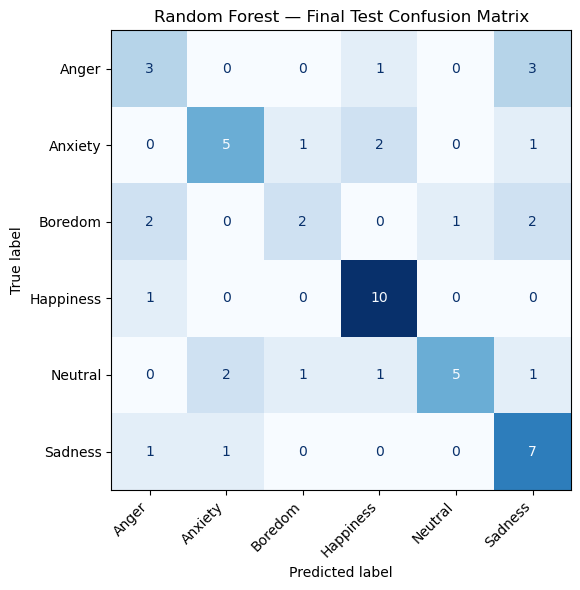

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=final_model.classes_,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax
)

ax.set_title("Random Forest — Final Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

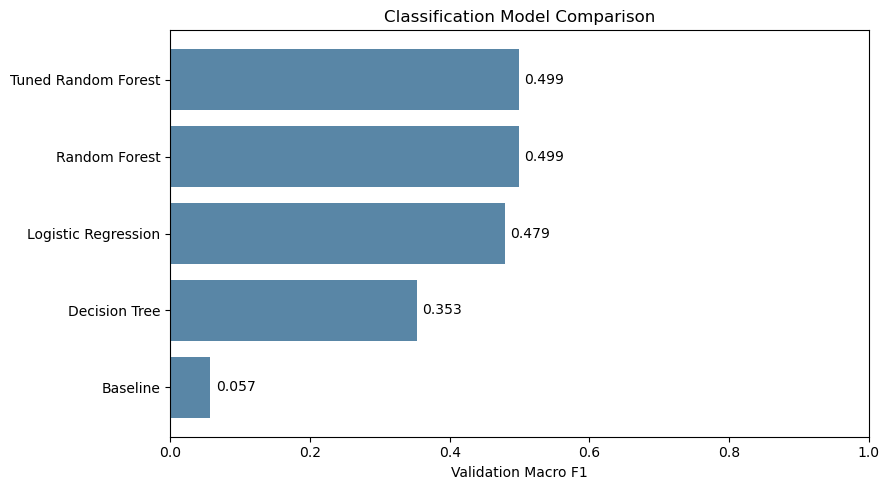

,Model,Train Accuracy (%),Validation Accuracy (%),Validation Macro F1
0,Tuned Random Forest,94.969,54.717,0.499
1,Random Forest,94.969,54.717,0.499
2,Logistic Regression,64.151,50.943,0.479
3,Decision Tree,61.635,39.623,0.353
4,Baseline,20.755,20.755,0.057


In [25]:
comparison_df = (
    pd.DataFrame(results)
    .sort_values("Validation Macro F1", ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    comparison_df["Model"],
    comparison_df["Validation Macro F1"],
    color="#5986A6"
)

ax.bar_label(bars, fmt="%.3f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Validation Macro F1")
ax.set_title("Classification Model Comparison")
plt.tight_layout()
plt.show()

display(comparison_df.round(3))

In [26]:
from pathlib import Path
import joblib

project_folder = Path.cwd() / "Himani_Verma_Capstone_Project_3"
project_folder.mkdir(exist_ok=True)

joblib.dump(
    final_model,
    project_folder / "emotion_classifier.joblib"
)

comparison_df.to_csv(
    project_folder / "model_comparison.csv",
    index=False
)

pd.DataFrame({
    "Actual_Emotion": y_test.to_numpy(),
    "Predicted_Emotion": test_predictions
}).to_csv(
    project_folder / "test_predictions.csv",
    index=False
)

pd.DataFrame([{
    "Model": selected_model_name,
    "Test_Records": len(y_test),
    "Test_Accuracy": test_accuracy,
    "Test_Macro_F1": test_macro_f1
}]).to_csv(
    project_folder / "final_test_metrics.csv",
    index=False
)

print("Model and results saved successfully!")
print("Project folder:", project_folder)

Model and results saved successfully!
Project folder: C:\Users\HP\Himani_Verma_Capstone_Project_3


### Results and Conclusion

Random Forest had the highest validation Macro F1 of 0.499,
with 54.72% validation accuracy. The parameter search selected
the same settings, so tuning did not improve its results.

After refitting on training and validation data, the final model
achieved 60.38% accuracy and a Macro F1 of 0.569 on 53 test records.

Happiness had the highest test F1-score at 0.800.
Boredom had the lowest recall at 0.286, showing that the model
missed many records in this category.

The gap between training and validation accuracy suggests
overfitting. The small dataset and its data-quality issues also
limit how widely these results can be applied.

This project predicts the dataset's emotion labels. It does not
show that social media usage causes an emotion or provide a
mental health diagnosis.